<a href="https://colab.research.google.com/github/vcasadei/Redes-Neurais-CESAR-School/blob/2026.01-A/2%20-%20Regress%C3%A3o%20Linear/2.6_regressao_linear_salarios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# 2- Regressão linear multivariável — California Housing

## Objetivos

- Aplicar regressão linear multivariável ao dataset California Housing.
- Utilizar as oito características para prever o preço das casas.
- Separar os dados em treino, validação e teste.
- Padronizar as características e o valor alvo.
- Treinar o modelo com nn.Linear, nn.MSELoss e optim.SGD.
- Avaliar o modelo no conjunto de teste e interpretar os pesos aprendidos.

O objetivo é prever o preço das casas na Califórnia utilizando oito características do conjunto California Housing.

O modelo utiliza regressão linear multivariável, combinando as oito entradas para produzir uma previsão de preço.

## Importação das bibliotecas

In [215]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

### Leitura

In [216]:
dados = fetch_california_housing(as_frame=True)

X, y = dados.data, dados.target

print('X shape:', X.shape)
print('y shape:', y.shape)

X.head()

X shape: (20640, 8)
y shape: (20640,)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


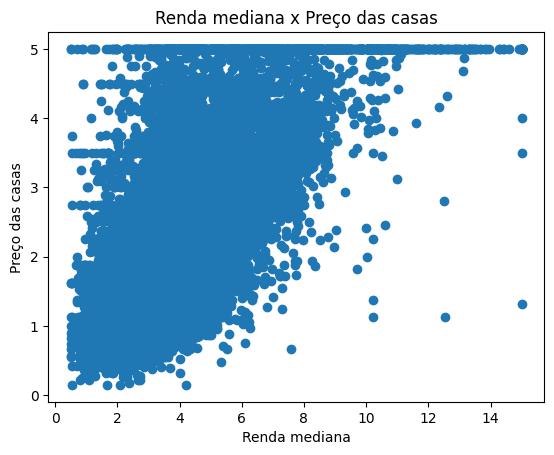

In [217]:
plt.scatter(X['MedInc'], y)
plt.xlabel('Renda mediana')
plt.ylabel('Preço das casas')
plt.title('Renda mediana x Preço das casas')
plt.show()

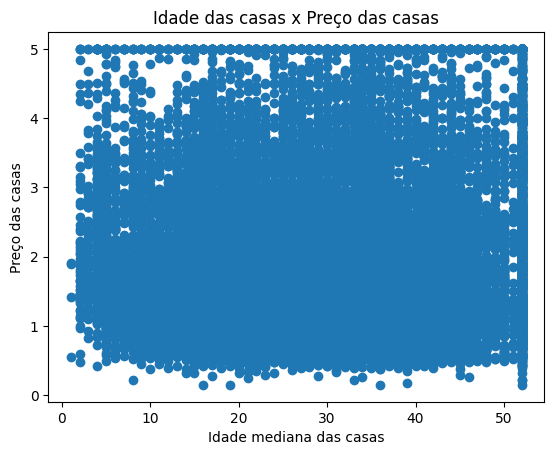

In [218]:
plt.scatter(X['HouseAge'], y)
plt.xlabel('Idade mediana das casas')
plt.ylabel('Preço das casas')
plt.title('Idade das casas x Preço das casas')
plt.show()

In [219]:
X.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000


### Significado das características

- **MedInc:** renda mediana dos moradores do distrito.
- **HouseAge:** idade mediana das casas.
- **AveRooms:** número médio de cômodos por domicílio.
- **AveBedrms:** número médio de quartos por domicílio.
- **Population:** população do distrito.
- **AveOccup:** número médio de moradores por domicílio.
- **Latitude:** latitude da localização.
- **Longitude:** longitude da localização.

A variável alvo (`target`) representa o valor mediano das casas, em unidades de 100 mil dólares.

### Treino × validação × teste

Os dados foram separados em três conjuntos: 70% para treino, 15% para validação e 15% para teste. O treino ajusta os parâmetros do modelo, a validação acompanha o desempenho durante o treinamento e o teste avalia o modelo em dados que não participaram dos ajustes.

In [220]:
x_raw = X.to_numpy()
y_raw = y.to_numpy().reshape(-1, 1)

x_train_raw, x_temp_raw, y_train_raw, y_temp_raw = train_test_split(
    x_raw, y_raw, test_size=0.3, random_state=42)

x_val_raw, x_test_raw, y_val_raw, y_test_raw = train_test_split(
    x_temp_raw, y_temp_raw, test_size=0.5, random_state=42)

print('treino:', x_train_raw.shape, y_train_raw.shape)
print('validação:', x_val_raw.shape, y_val_raw.shape)
print('teste:', x_test_raw.shape, y_test_raw.shape)

treino: (14448, 8) (14448, 1)
validação: (3096, 8) (3096, 1)
teste: (3096, 8) (3096, 1)


In [221]:
x_scaler = StandardScaler()
y_scaler = StandardScaler()

x_train = x_scaler.fit_transform(x_train_raw)
x_val = x_scaler.transform(x_val_raw)
x_test = x_scaler.transform(x_test_raw)

y_train = y_scaler.fit_transform(y_train_raw)
y_val = y_scaler.transform(y_val_raw)
y_test = y_scaler.transform(y_test_raw)

print('x_train:', x_train.shape)
print('x_val:', x_val.shape)
print('x_test:', x_test.shape)

x_train: (14448, 8)
x_val: (3096, 8)
x_test: (3096, 8)


In [222]:
x_train = torch.from_numpy(x_train).float()
x_val = torch.from_numpy(x_val).float()
x_test = torch.from_numpy(x_test).float()

y_train = torch.from_numpy(y_train).float()
y_val = torch.from_numpy(y_val).float()
y_test = torch.from_numpy(y_test).float()

## Modelo

`nn.Linear(8, 1)` recebe oito características de entrada e produz uma previsão.

- `model.weight` contém os oito pesos aprendidos.
- `model.bias` contém o bias, que é o termo independente.

Como as características foram padronizadas, os pesos podem ser comparados para analisar a influência relativa de cada variável no modelo.

In [223]:
model = nn.Linear(8, 1)
print('weight:', model.weight)
print('bias:', model.bias)

weight: Parameter containing:
tensor([[-0.3331, -0.0694, -0.1698, -0.0943, -0.3123,  0.1419, -0.3169, -0.0225]],
       requires_grad=True)
bias: Parameter containing:
tensor([0.1229], requires_grad=True)


### Testando o predict da rede

In [224]:
model(torch.ones(5, 8))

tensor([[-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536],
        [-1.0536]], grad_fn=<AddmmBackward0>)

In [225]:
model(x_train[:3])

tensor([[0.3319],
        [0.9249],
        [0.4498]], grad_fn=<AddmmBackward0>)

## Treinamento

### Função de custo e otimizador

Os mesmos do 2.5.

In [226]:
lr = 0.3
criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)   # atualiza weight e bias

### Funções de treino e de validação

O código de uma época vira duas funções:

- `train_epoch` realiza uma etapa de treinamento utilizando todo o conjunto de treino.
- `validate_epoch` calcula o custo na validação, sem atualizar os parâmetros.

`model.train()` e `model.eval()` definem o modo do modelo. `torch.no_grad()` evita registrar operações de gradiente durante a validação.

In [227]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()            # modo de treino
    optimizer.zero_grad()

    # forward
    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    # backward e otimizador
    loss.backward()
    optimizer.step()

    return loss.item()       # custo como número Python

In [228]:
def validate_epoch(model, criterion, x_val, y_val):
    model.eval()             # modo de avaliação
    with torch.no_grad():    # sem grafo do autograd: não haverá backward
        y_pred = model(x_val)
        loss = criterion(y_pred, y_val)
    return loss.item()

### Laço de treinamento

A cada época, o modelo realiza uma etapa de treinamento e calcula a perda na validação. Os valores das perdas são armazenados em `train_losses` e `val_losses` para acompanhar o desempenho ao longo das épocas.

In [229]:
n_epochs = 120
train_losses = []
val_losses = []

for epoch in range(n_epochs):
    train_loss = train_epoch(model, optimizer, criterion, x_train, y_train)
    train_losses.append(train_loss)

    val_loss = validate_epoch(model, criterion, x_val, y_val)
    val_losses.append(val_loss)

    if (epoch + 1) % 20 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], Train Loss: {train_loss:.6f}, Val Loss: {val_loss:.6f}')

Epoch[20/120], Train Loss: 0.402168, Val Loss: 0.413673
Epoch[40/120], Train Loss: 0.392304, Val Loss: 0.405145
Epoch[60/120], Train Loss: 0.390904, Val Loss: 0.403969
Epoch[80/120], Train Loss: 0.390696, Val Loss: 0.403794
Epoch[100/120], Train Loss: 0.390662, Val Loss: 0.403759
Epoch[120/120], Train Loss: 0.390656, Val Loss: 0.403746


## Avaliação

### Curvas de custo de treino e de validação

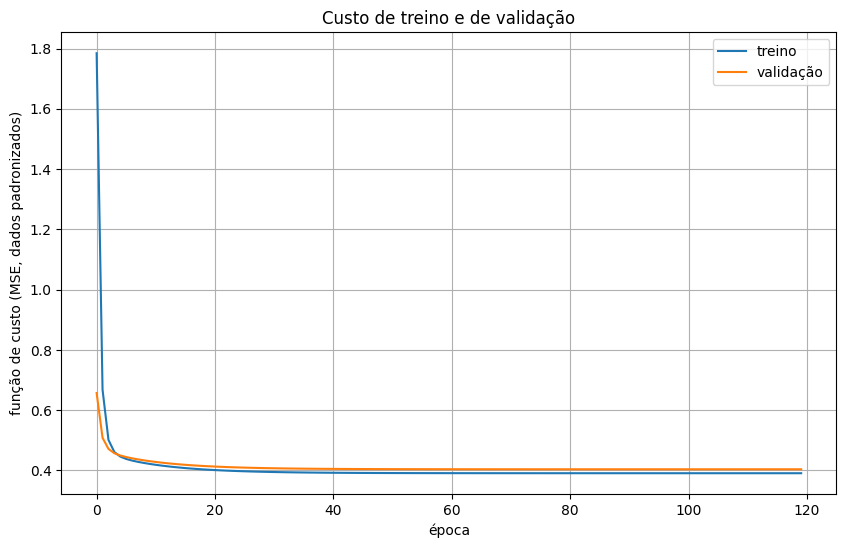

In [230]:
plt.figure(figsize=(10, 6))
plt.plot(range(n_epochs), train_losses, label='treino')
plt.plot(range(n_epochs), val_losses, label='validação')
plt.xlabel('época')
plt.ylabel('função de custo (MSE, dados padronizados)')
plt.title('Custo de treino e de validação')
plt.legend()
plt.grid(True)
plt.show()

### Parâmetros treinados (na escala padronizada)

In [231]:
print('Pesos:', model.weight.detach().numpy())
print('Bias:', model.bias.item())
print(f'MSE final treino: {train_losses[-1]:.4f}')
print(f'MSE final validação: {val_losses[-1]:.4f}')

Pesos: [[ 7.3457479e-01  1.0594097e-01 -2.5995615e-01  3.0172789e-01
  -6.1684003e-04 -3.6091752e-02 -7.6829809e-01 -7.4657321e-01]]
Bias: 1.3551982647186378e-08
MSE final treino: 0.3907
MSE final validação: 0.4037


In [232]:
pesos = model.weight.detach().numpy().flatten()

tabela_pesos = pd.DataFrame({
    'Característica': X.columns,
    'Peso': pesos
})

print(tabela_pesos)

  Característica      Peso
0         MedInc  0.734575
1       HouseAge  0.105941
2       AveRooms -0.259956
3      AveBedrms  0.301728
4     Population -0.000617
5       AveOccup -0.036092
6       Latitude -0.768298
7      Longitude -0.746573


In [233]:
# Previsões no conjunto de teste
model.eval()

with torch.no_grad():
    y_pred = model(x_test).numpy()

# Voltar os valores para a escala original
y_pred_original = y_scaler.inverse_transform(y_pred)

# RMSE do modelo em dólares
rmse_modelo = np.sqrt(np.mean(
    (y_pred_original - y_test_raw) ** 2
)) * 100000

print(f'RMSE do modelo: US$ {rmse_modelo:,.2f}')

RMSE do modelo: US$ 72,130.25


In [234]:
# Previsão usando a média dos preços do treino
y_pred_media = np.full_like(y_test_raw, y_train_raw.mean())

# RMSE da referência em dólares
rmse_media = np.sqrt(np.mean(
    (y_pred_media - y_test_raw) ** 2
)) * 100000

print(f'RMSE da média: US$ {rmse_media:,.2f}')

RMSE da média: US$ 114,992.22


### Conclusão

O modelo de regressão linear multivariável apresentou RMSE de **US$ 72.130,25** no conjunto de teste, enquanto o modelo de referência, que prevê sempre a média dos preços do treino, apresentou RMSE de **US$ 114.992,22**.

Portanto, o modelo treinado apresentou desempenho melhor que a referência, mostrando que as oito características contribuem para a previsão dos preços das casas.

Entre os pesos aprendidos, MedInc apresentou associação positiva importante, enquanto Latitude e Longitude apresentaram associações negativas de maior magnitude. Population apresentou peso próximo de zero.

Apesar do resultado melhor que a referência, o modelo ainda apresenta erros consideráveis. Seu desempenho poderia ser investigado com outros modelos ou técnicas mais avançadas.